# 1. Análisis Exploratorio de Datos (EDA)

**Instrucciones generales:** Usa este notebook para realizar el EDA del **dataset que seleccionaste** en la actividad *Selección de la situación problema*. En cada apartado encontrarás una celda de **instrucciones** y, a continuación, una celda de **código** para tu implementación.

In [ ]:
# Configuración general
# DATA_PATH = 'ruta/a/tu/dataset.csv'

## 1. Importación de librerías
Cargamos las librerías necesarias. Usaremos **pandas** para manipulación de datos y **matplotlib** para visualización.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carga e inspección inicial de los datos
- Importa las librerías básicas: **pandas**, **numpy**, **matplotlib**, **seaborn**.
- Carga el dataset (`pd.read_csv()`, `pd.read_excel()`, etc.).
- Revisa:
  - `df.shape` → tamaño del dataset (filas, columnas)
  - `df.info()` → tipos de datos y valores nulos
  - `df.head()` / `df.sample()` → primeras filas para una vista general
  - `df.describe()` → estadísticas descriptivas (promedio, desviación, min, max, cuartiles)


In [ ]:
df = pd.read_csv('logs.csv')
df.shape
df.info()
df.head()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527664 entries, 0 to 527663
Data columns (total 44 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   _id                          527664 non-null  object 
 1   _ignored                     0 non-null       float64
 2   _index                       527664 non-null  object 
 3   _score                       527664 non-null  float64
 4   @timestamp                   527664 non-null  object 
 5   @version                     527664 non-null  int64  
 6   event_code_version           527664 non-null  object 
 7   event_hash                   527664 non-null  object 
 8   @event_time_requested        527664 non-null  object 
 9   headers_content_type         527664 non-null  object 
 10  headers_http_host            527664 non-null  object 
 11  headers_http_request_method  527664 non-null  object 
 12  heathers_request_path        527664 non-null  object 
 13 

,_id,_ignored,_index,_score,@timestamp,@version,event_code_version,event_hash,@event_time_requested,headers_content_type,...,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_status,llm_error_message,llm_cost_usd,llm_temperature,llm_top_p,llm_stream,llm_finish_reason
count,527664,0.0,527664,527664.000000,527664,527664.0,527664,527664,527664,527664,...,210692.000000,210692.000000,147518.000000,210692,63174,210692.000000,210692.000000,210692.000000,210692,210692
unique,527664,NaN,2,NaN,351962,NaN,300,527664,527337,5,...,NaN,NaN,NaN,3,217,NaN,NaN,NaN,2,4
top,3a0460c8-fe40-46fa-95e4-43c28a5f97d8,NaN,sap-logs-2026.04,NaN,2026-04-16T23:53:58.000Z,NaN,1.8.9,192ed275f8e88525244992e8a91d665d6ee37b342b133d...,2026-04-15T00:32:12.727Z,application/json,...,NaN,NaN,NaN,success,Request timed out after 30 s.,NaN,NaN,NaN,True,stop
freq,1,NaN,316971,NaN,8,NaN,1872,1,2,105797,...,NaN,NaN,NaN,147518,20915,NaN,NaN,NaN,105404,103415
mean,NaN,NaN,NaN,0.750152,NaN,1.0,NaN,NaN,NaN,NaN,...,1787.135539,8767.656070,16496.031223,NaN,NaN,0.012453,0.748580,0.750161,NaN,NaN
std,NaN,NaN,NaN,0.144422,NaN,0.0,NaN,NaN,NaN,NaN,...,707.141584,8714.933584,9391.407513,NaN,NaN,0.018861,0.432486,0.144353,NaN,NaN
min,NaN,NaN,NaN,0.500000,NaN,1.0,NaN,NaN,NaN,NaN,...,82.000000,200.090000,256.000000,NaN,NaN,0.000008,0.000000,0.500000,NaN,NaN
25%,NaN,NaN,NaN,0.625200,NaN,1.0,NaN,NaN,NaN,NaN,...,1271.000000,2304.755000,8353.000000,NaN,NaN,0.000742,0.370000,0.630000,NaN,NaN
50%,NaN,NaN,NaN,0.750500,NaN,1.0,NaN,NaN,NaN,NaN,...,1789.000000,6517.820000,16454.500000,NaN,NaN,0.005412,0.750000,0.750000,NaN,NaN
75%,NaN,NaN,NaN,0.875200,NaN,1.0,NaN,NaN,NaN,NaN,...,2303.000000,11819.862500,24639.000000,NaN,NaN,0.014664,1.120000,0.870000,NaN,NaN


## 3. Identificación de tipos de variables
Clasifica las columnas:
- **Numéricas continuas**: edad, salario, temperatura
- **Numéricas discretas**: número de hijos, cantidad de productos
- **Categóricas**: género, país, color
- **Ordinales**: nivel de educación, satisfacción (bajo, medio, alto)
- **Fechas o temporales**: fecha de compra, hora del evento


In [ ]:
# Identificación de tipos de variables en el dataset logs

# 1. Variables Temporales / Fechas
temporales = ['@timestamp', '@event_time_requested']

# 2. Variables Numéricas Continuas (Mediciones físicas, costos o métricas continuas)
numericas_continuas = [
    'sap_llm_response_size', 'sap_llm_response_time',
    'llm_prompt_tokens', 'llm_completion_tokens', 'llm_total_tokens',
    'llm_response_time_ms', 'llm_response_size_bytes', 'llm_cost_usd',
    'llm_temperature', 'llm_top_p'
]

# 3. Variables Numéricas Discretas
numericas_discretas = ['@version']  # En este dataset actúa como una versión entera

# 4. Variables Categóricas (Clasificación sin orden intrínseco)
categoricas = [
    '_index', 'event_code_version', 'headers_content_type', 'headers_http_host',
    'headers_http_request_method', 'heathers_request_path', 'sap_function_application',
    'sap_source_type', 'sap_function_log_type', 'sap_app_env',
    'region_id', 'region_name', 'region_code', 'macro_region',
    'http_status_code', 'llm_model_id', 'llm_provider',
    'llm_prompt_category', 'llm_status', 'llm_stream', 'llm_finish_reason'
]

# 5. Variables Especiales o que no aplican directamente a las 5 categorías estándar:
# - Identificadores Únicos (IDs/Hashes): No son categóricas tradicionales porque no agrupan registros.
# - Texto Libre / No Estructurado: Contenido libre, mensajes de error o prompts de usuario.
# - Columnas nulas/descartables: No aportan información.

identificadores = ['_id', 'event_hash', 'service_id', 'client_ip', 'llm_prompt_id']
texto_libre = ['sap_function_message', 'llm_prompt', 'llm_error_message']
sin_informacion = ['_ignored', '_score'] # _score es constante/metadato y _ignored es completamente nulo

# Imprimir el resumen de la clasificación
print("=== CLASIFICACIÓN DE COLUMNAS ===\n")
print(f"Fechas o temporales ({len(temporales)}):\n   {temporales}\n")
print(f"Numéricas continuas ({len(numericas_continuas)}):\n   {numericas_continuas}\n")
print(f"Numéricas discretas ({len(numericas_discretas)}):\n   {numericas_discretas}\n")
print(f"Categóricas ({len(categoricas)}):\n   {categoricas}\n")
print(f"Identificadores Únicos / Hashes ({len(identificadores)}):\n   {identificadores}\n")
print(f"Texto Libre / No estructurado ({len(texto_libre)}):\n   {texto_libre}\n")
print(f"Sin Información / Nulas ({len(sin_informacion)}):\n   {sin_informacion}")


=== CLASIFICACIÓN DE COLUMNAS ===

Fechas o temporales (2):
   ['@timestamp', '@event_time_requested']

Numéricas continuas (10):
   ['sap_llm_response_size', 'sap_llm_response_time', 'llm_prompt_tokens', 'llm_completion_tokens', 'llm_total_tokens', 'llm_response_time_ms', 'llm_response_size_bytes', 'llm_cost_usd', 'llm_temperature', 'llm_top_p']

Numéricas discretas (1):
   ['@version']

Categóricas (21):
   ['_index', 'event_code_version', 'headers_content_type', 'headers_http_host', 'headers_http_request_method', 'heathers_request_path', 'sap_function_application', 'sap_source_type', 'sap_function_log_type', 'sap_app_env', 'region_id', 'region_name', 'region_code', 'macro_region', 'http_status_code', 'llm_model_id', 'llm_provider', 'llm_prompt_category', 'llm_status', 'llm_stream', 'llm_finish_reason']

Identificadores Únicos / Hashes (5):
   ['_id', 'event_hash', 'service_id', 'client_ip', 'llm_prompt_id']

Texto Libre / No estructurado (3):
   ['sap_function_message', 'llm_prompt'

## 4. Limpieza de datos
**Valores faltantes:**
- Identificar (`df.isnull().sum()`)
- Decidir si se imputan (media, mediana, moda, interpolación) o se eliminan.

**Duplicados:**
- Detectar (`df.duplicated()`) y eliminar (`df.drop_duplicates()`).

**Outliers (valores atípicos):**
- Detectar mediante **boxplots**, **z-score** o **rango intercuartílico (IQR)**.
- Analizar si son errores o casos reales.
- Borrar algunos *outliers* si es necesario.

**Tipos de datos incorrectos:**
- Convertir *strings* a fechas (`pd.to_datetime()`), numéricos, etc.


In [ ]:
# ==========================================
# 1. IDENTIFICACIÓN DE VALORES FALTANTES
# ==========================================

# Calcular total de valores nulos y su porcentaje por columna
null_info = pd.DataFrame({
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Valores Nulos', ascending=False)

# Filtrar para mostrar solo las columnas que contienen nulos
null_info_filtered = null_info[null_info['Valores Nulos'] > 0]
print("=== COLUMNAS CON VALORES NULOS ===")
display(null_info_filtered)

# ==========================================
# 2. DECISIÓN Y TRATAMIENTO (EJEMPLOS DE IMPUTACIÓN)
# ==========================================

# Creamos una copia para aplicar las pruebas de limpieza sin alterar el original de inmediato
df_cleaned = df.copy()

# --- Caso A: Eliminar columnas con 100% de nulos ---
# '_ignored' tiene 100% de nulos, por lo que no aporta información.
df_cleaned.drop(columns=['_ignored'], inplace=True, errors='ignore')
print("\n[Acción] Columna '_ignored' eliminada por contener 100% de valores nulos.")

# --- Caso B: Imputación en variables numéricas continuas (usando la Mediana) ---
# Usamos la mediana en métricas como tiempos de respuesta para evitar distorsiones por outliers
numericas_a_imputar = ['sap_llm_response_size', 'sap_llm_response_time', 'llm_response_size_bytes']
for col in numericas_a_imputar:
    if col in df_cleaned.columns:
        mediana = df_cleaned[col].median()
        df_cleaned[col] = df_cleaned[col].fillna(mediana)
        print(f"[Acción] Columna '{col}' imputada con su mediana: {mediana:.2f}")

# --- Caso C: Imputación en variables categóricas (usando un valor constante o 'Desconocido') ---
# En logs, si 'llm_provider' o 'llm_model_id' son nulos, usualmente significa que no se usó LLM en esa petición.
categoricas_a_imputar = ['llm_provider', 'llm_model_id', 'llm_prompt_category']
for col in categoricas_a_imputar:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].fillna('No_Aplica')
        print(f"[Acción] Columna '{col}' imputada con la etiqueta: 'No_Aplica'")

# --- Caso D: Imputación con la Moda (Valor más frecuente) ---
# Útil para categóricas donde sí se espera que siempre exista un valor
if 'service_id' in df_cleaned.columns:
    moda_service = df_cleaned['service_id'].mode()[0]
    df_cleaned['service_id'] = df_cleaned['service_id'].fillna(moda_service)
    print(f"[Acción] Columna 'service_id' imputada con su moda: '{moda_service}'")

# --- Caso E: Conservar los nulos como una categoría informativa ---
# En 'llm_error_message', un valor nulo significa 'Sin Error', por lo que lo reemplazamos explícitamente
if 'llm_error_message' in df_cleaned.columns:
    df_cleaned['llm_error_message'] = df_cleaned['llm_error_message'].fillna('Sin_Error')
    print("[Acción] Columna 'llm_error_message' imputada con la constante 'Sin_Error'")

# Verificar que hayamos reducido o eliminado los nulos en las columnas tratadas
print("\n=== CONTEO DE NULOS EN EL DATASET LIMPIO (MUESTRA) ===")
print(df_cleaned[["sap_llm_response_size", "llm_provider", "llm_error_message"]].isnull().sum())


=== COLUMNAS CON VALORES NULOS ===


,Valores Nulos,Porcentaje (%)
_ignored,527664,100.000000
llm_error_message,464490,88.027608
llm_response_size_bytes,380146,72.043194
sap_llm_response_size,380145,72.043005
llm_finish_reason,316972,60.070803
llm_status,316972,60.070803
llm_stream,316972,60.070803
llm_cost_usd,316972,60.070803
llm_completion_tokens,316972,60.070803
llm_top_p,316972,60.070803



[Acción] Columna '_ignored' eliminada por contener 100% de valores nulos.
[Acción] Columna 'sap_llm_response_size' imputada con su mediana: 16455.00
[Acción] Columna 'sap_llm_response_time' imputada con su mediana: 6517.84
[Acción] Columna 'llm_response_size_bytes' imputada con su mediana: 16454.50
[Acción] Columna 'llm_provider' imputada con la etiqueta: 'No_Aplica'
[Acción] Columna 'llm_model_id' imputada con la etiqueta: 'No_Aplica'
[Acción] Columna 'llm_prompt_category' imputada con la etiqueta: 'No_Aplica'
[Acción] Columna 'service_id' imputada con su moda: 'analytics-engine'
[Acción] Columna 'llm_error_message' imputada con la constante 'Sin_Error'

=== CONTEO DE NULOS EN EL DATASET LIMPIO (MUESTRA) ===
sap_llm_response_size    0
llm_provider             0
llm_error_message        0
dtype: int64


In [ ]:
# ==========================================
# 2. DETECCIÓN Y TRATAMIENTO DE DUPLICADOS
# ==========================================

# A. Verificar duplicados absolutos (filas completamente idénticas)
duplicados_totales = df_cleaned.duplicated().sum()
print(f"Cantidad de filas completamente duplicadas en df_cleaned: {duplicados_totales}")

# B. Verificar duplicados en identificadores clave (ej. '_id' o 'event_hash')
if '_id' in df_cleaned.columns:
    duplicados_id = df_cleaned.duplicated(subset=['_id']).sum()
    print(f"Cantidad de registros con el mismo '_id' repetido: {duplicados_id}")

# C. Eliminar filas duplicadas (si existen)
if duplicados_totales > 0:
    # Eliminamos duplicados absolutos y actualizamos el DataFrame
    df_cleaned = df_cleaned.drop_duplicates(keep='first')
    print("[Acción] Se han eliminado los registros duplicados absolutos, conservando la primera aparición.")
else:
    print("[Información] No se encontraron registros duplicados absolutos. No es necesario eliminar filas.")

# Mostrar el nuevo tamaño del dataset limpio
print(f"Tamaño del DataFrame original: {df.shape}")
print(f"Tamaño del DataFrame limpio actual: {df_cleaned.shape}")


Cantidad de filas completamente duplicadas en df_cleaned: 0
Cantidad de registros con el mismo '_id' repetido: 0
[Información] No se encontraron registros duplicados absolutos. No es necesario eliminar filas.
Tamaño del DataFrame original: (527664, 44)
Tamaño del DataFrame limpio actual: (527664, 43)


=== ANÁLISIS DE OUTLIERS USANDO EL MÉTODO IQR ===

Columna: 'llm_response_time_ms'
   - Rango normal esperado: [-11967.9062 a 26092.5237]
   - Cantidad de outliers detectados: 20915 de 210692 registros
   - Porcentaje de outliers: 9.93%
   - Valor máximo registrado: 34998.1600

Columna: 'llm_cost_usd'
   - Rango normal esperado: [-0.0201 a 0.0355]
   - Cantidad de outliers detectados: 22012 de 210692 registros
   - Porcentaje de outliers: 10.45%
   - Valor máximo registrado: 0.1394

Columna: 'llm_total_tokens'
   - Rango normal esperado: [-277.0000 a 3851.0000]
   - Cantidad de outliers detectados: 0 de 210692 registros
   - Porcentaje de outliers: 0.00%
   - Valor máximo registrado: 3494.0000



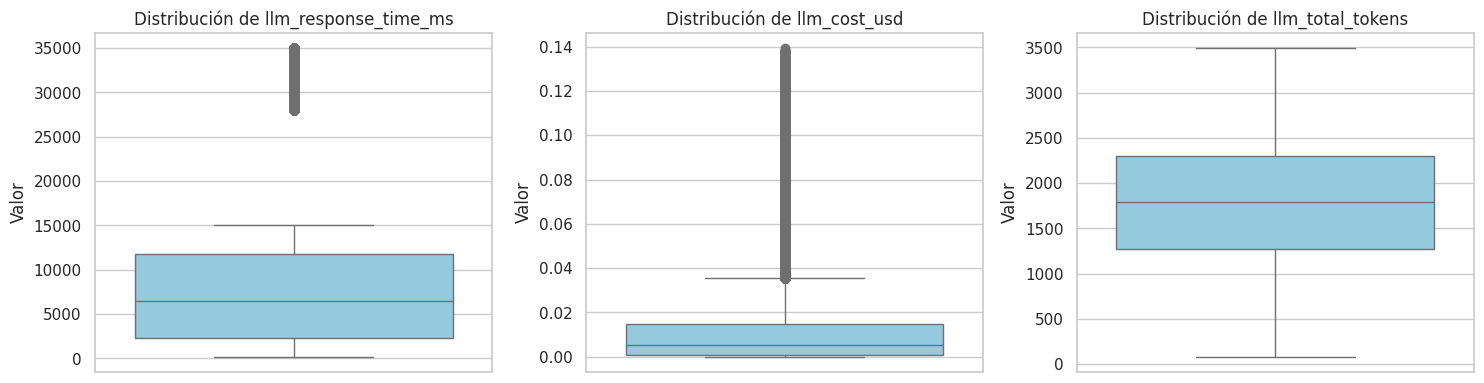

In [ ]:
# ==========================================
# 3. DETECCIÓN Y ANÁLISIS DE OUTLIERS (VALORES ATÍPICOS)
# ==========================================

# Seleccionamos algunas variables numéricas continuas clave para el análisis
columnas_numericas = ['llm_response_time_ms', 'llm_cost_usd', 'llm_total_tokens']

print("=== ANÁLISIS DE OUTLIERS USANDO EL MÉTODO IQR ===\n")

for col in columnas_numericas:
    if col in df_cleaned.columns:
        # Eliminar nulos temporalmente solo para el cálculo matemático
        datos_col = df_cleaned[col].dropna()

        if len(datos_col) > 0:
            # Calcular cuartiles y rango intercuartílico
            q1 = datos_col.quantile(0.25)
            q3 = datos_col.quantile(0.75)
            iqr = q3 - q1

            # Límites para considerar un valor como atípico
            limite_inferior = q1 - 1.5 * iqr
            limite_superior = q3 + 1.5 * iqr

            # Identificar atípicos
            outliers = datos_col[(datos_col < limite_inferior) | (datos_col > limite_superior)]
            porcentaje_outliers = (len(outliers) / len(datos_col)) * 100

            print(f"Columna: '{col}'")
            print(f"   - Rango normal esperado: [{limite_inferior:.4f} a {limite_superior:.4f}]")
            print(f"   - Cantidad de outliers detectados: {len(outliers)} de {len(datos_col)} registros")
            print(f"   - Porcentaje de outliers: {porcentaje_outliers:.2f}%")
            print(f"   - Valor máximo registrado: {datos_col.max():.4f}\n")

# Generar boxplots para visualizar la distribución espacial de los outliers
plt.figure(figsize=(15, 4))
for i, col in enumerate(columnas_numericas, 1):
    if col in df_cleaned.columns:
        plt.subplot(1, 3, i)
        sns.boxplot(y=df_cleaned[col], color='skyblue')
        plt.title(f'Distribución de {col}')
        plt.ylabel('Valor')

plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# 4. CORRECCIÓN DE TIPOS DE DATOS INCORRECTOS
# ==========================================

print("=== TIPOS DE DATOS ANTES DE LA CONVERSIÓN ===")
print(df_cleaned[['@timestamp', '@event_time_requested']].dtypes)

# A. Convertir variables de fecha (de tipo object/string a datetime)
temporales_columnas = ['@timestamp', '@event_time_requested']
for col in temporales_columnas:
    if col in df_cleaned.columns:
        # Convertimos usando parseo de formato estándar ISO 8601 (con soporte de zona horaria UTC)
        df_cleaned[col] = pd.to_datetime(df_cleaned[col], errors='coerce')
        print(f"\n[Acción] Columna '{col}' convertida exitosamente a tipo Datetime.")

# B. Convertir http_status_code a entero (removiendo decimales que se crearon por los nulos)
if 'http_status_code' in df_cleaned.columns:
    # Usamos Int64 (con mayúscula) que soporta valores nulos sin forzar la columna a float
    df_cleaned['http_status_code'] = df_cleaned['http_status_code'].astype('Int64')
    print("[Acción] Columna 'http_status_code' convertida a tipo de dato entero (Int64).")

# C. Mostrar el resumen final de tipos de datos corregidos
print("\n=== TIPOS DE DATOS DESPUÉS DE LA CONVERSIÓN ===")
print(df_cleaned[['@timestamp', '@event_time_requested', 'http_status_code']].dtypes)


=== TIPOS DE DATOS ANTES DE LA CONVERSIÓN ===
@timestamp               object
@event_time_requested    object
dtype: object

[Acción] Columna '@timestamp' convertida exitosamente a tipo Datetime.

[Acción] Columna '@event_time_requested' convertida exitosamente a tipo Datetime.
[Acción] Columna 'http_status_code' convertida a tipo de dato entero (Int64).

=== TIPOS DE DATOS DESPUÉS DE LA CONVERSIÓN ===
@timestamp               datetime64[ns, UTC]
@event_time_requested    datetime64[ns, UTC]
http_status_code                       Int64
dtype: object


## 4. Análisis univariado
Analiza cada variable individualmente:
- **Numéricas**: histogramas, boxplots, medidas de tendencia y dispersión.
- **Categóricas**: conteos, porcentajes, gráficos de barras.
- **Fechas**: conteo de eventos por día, mes, año.

**Objetivo:** entender la distribución, detectar sesgos o escalas anómalas.


/tmp/ipykernel_4510/2113466795.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, y='llm_provider', order=order_provider, palette='viridis')
/tmp/ipykernel_4510/2113466795.py:33: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  temporal_series = df_cleaned.set_index('@timestamp').resample('H').size()


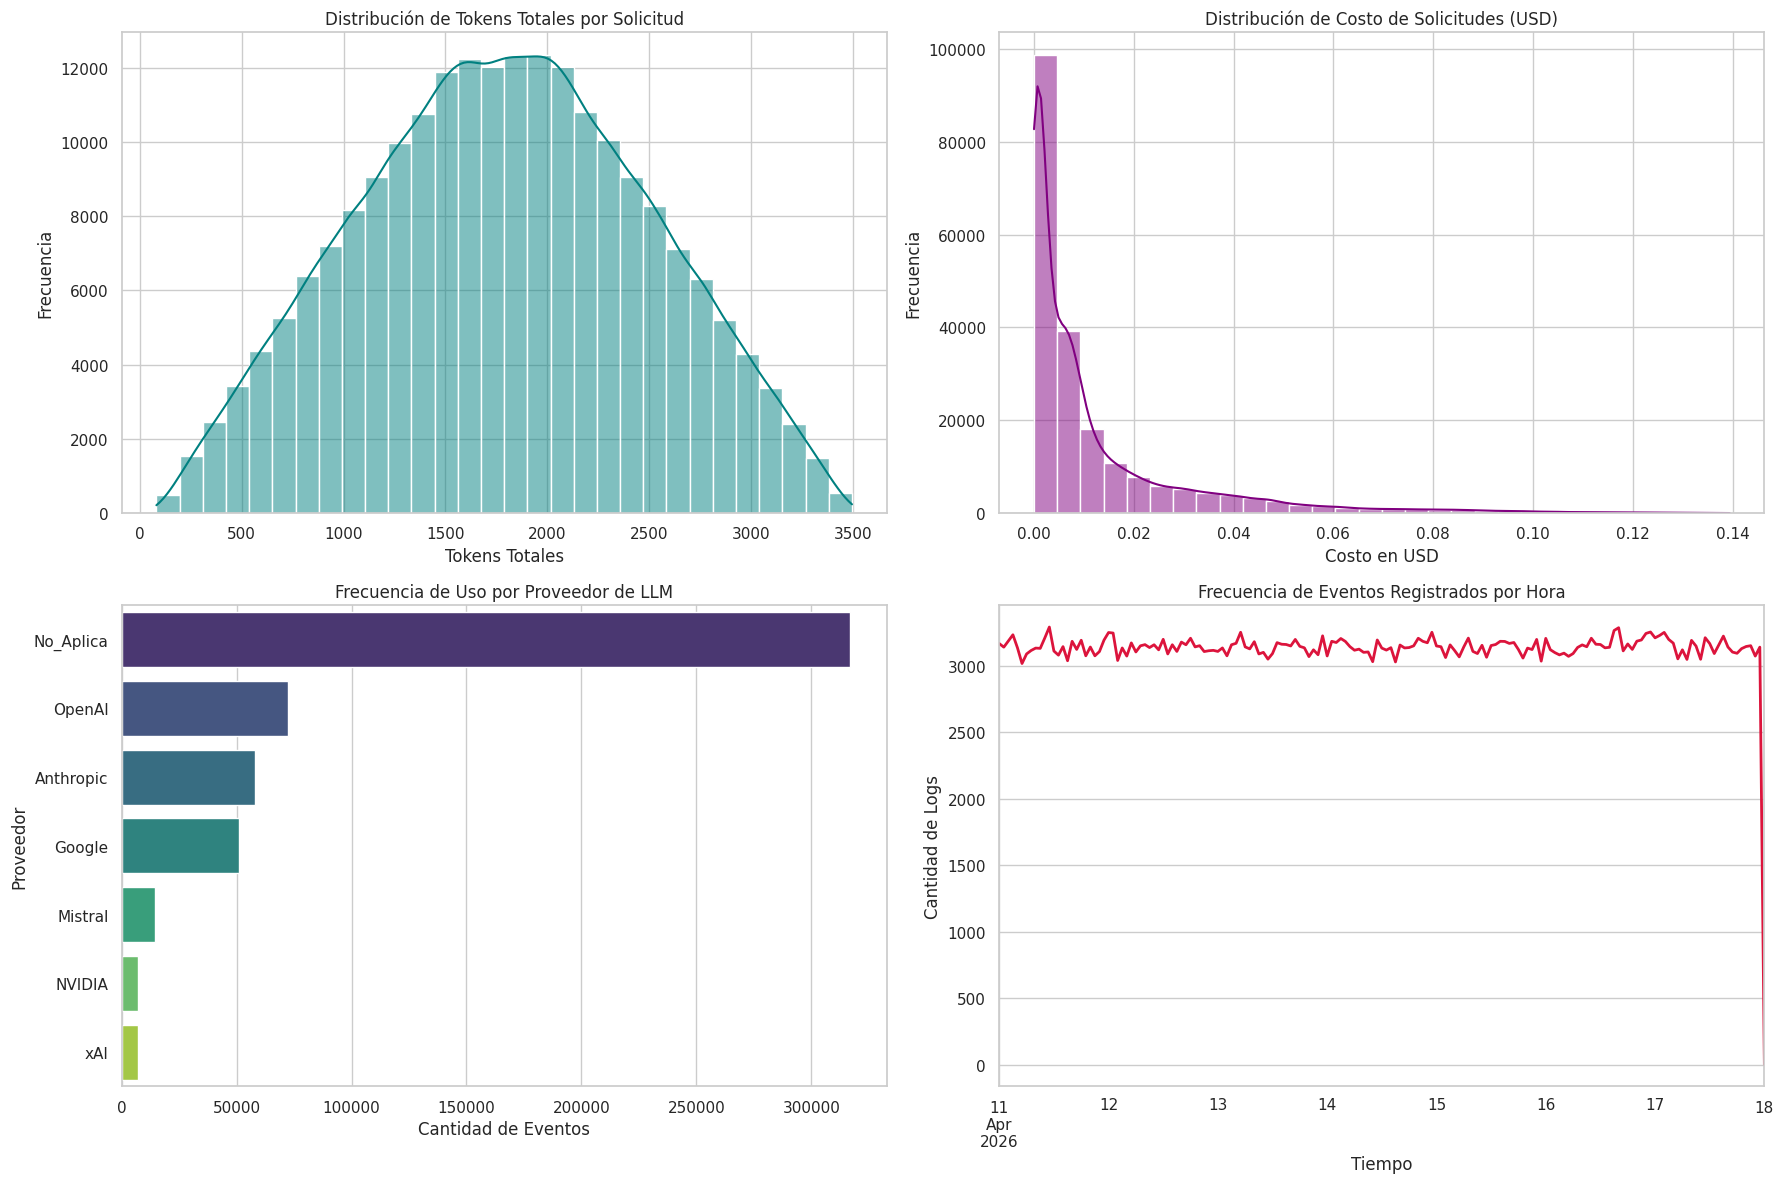

=== PROPORCIÓN DE EVENTOS POR PROVEEDOR DE LLM ===
llm_provider
No_Aplica    60.070613
OpenAI       13.728244
Anthropic    10.971565
Google        9.705798
Mistral       2.763312
NVIDIA        1.383646
xAI           1.376823
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# 5. ANÁLISIS UNIVARIADO
# ==========================================

# Configurar estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(18, 12))

# 1. Variables Numéricas: Distribución de Costo e Histograma de Tokens
plt.subplot(2, 2, 1)
sns.histplot(data=df_cleaned, x='llm_total_tokens', bins=30, kde=True, color='teal')
plt.title('Distribución de Tokens Totales por Solicitud')
plt.xlabel('Tokens Totales')
plt.ylabel('Frecuencia')

plt.subplot(2, 2, 2)
sns.histplot(data=df_cleaned, x='llm_cost_usd', bins=30, kde=True, color='purple')
plt.title('Distribución de Costo de Solicitudes (USD)')
plt.xlabel('Costo en USD')
plt.ylabel('Frecuencia')

# 2. Variables Categóricas: Distribución de Proveedores de LLM
plt.subplot(2, 2, 3)
order_provider = df_cleaned['llm_provider'].value_counts().index
sns.countplot(data=df_cleaned, y='llm_provider', order=order_provider, palette='viridis')
plt.title('Frecuencia de Uso por Proveedor de LLM')
plt.xlabel('Cantidad de Eventos')
plt.ylabel('Proveedor')

# 3. Tendencia Temporal: Eventos registrados por hora
plt.subplot(2, 2, 4)
# Agrupamos por hora utilizando la columna temporal ya convertida
temporal_series = df_cleaned.set_index('@timestamp').resample('H').size()
temporal_series.plot(color='crimson', linewidth=2)
plt.title('Frecuencia de Eventos Registrados por Hora')
plt.xlabel('Tiempo')
plt.ylabel('Cantidad de Logs')

plt.tight_layout()
plt.show()

# Mostrar estadísticas descriptivas de texto de las variables categóricas clave
print("=== PROPORCIÓN DE EVENTOS POR PROVEEDOR DE LLM ===")
print(df_cleaned['llm_provider'].value_counts(normalize=True) * 100)


## 5. Análisis bivariado y multivariado
Explora relaciones entre variables:
- **Numérica vs numérica**: scatter, correlación (`df.corr()`), mapa de calor.
- **Numérica vs categórica**: boxplots, *violin plots*, ANOVA.
- **Categórica vs categórica**: tablas de contingencia, barras apiladas.
- **Con la variable objetivo**: detectar patrones que expliquen el *target*.


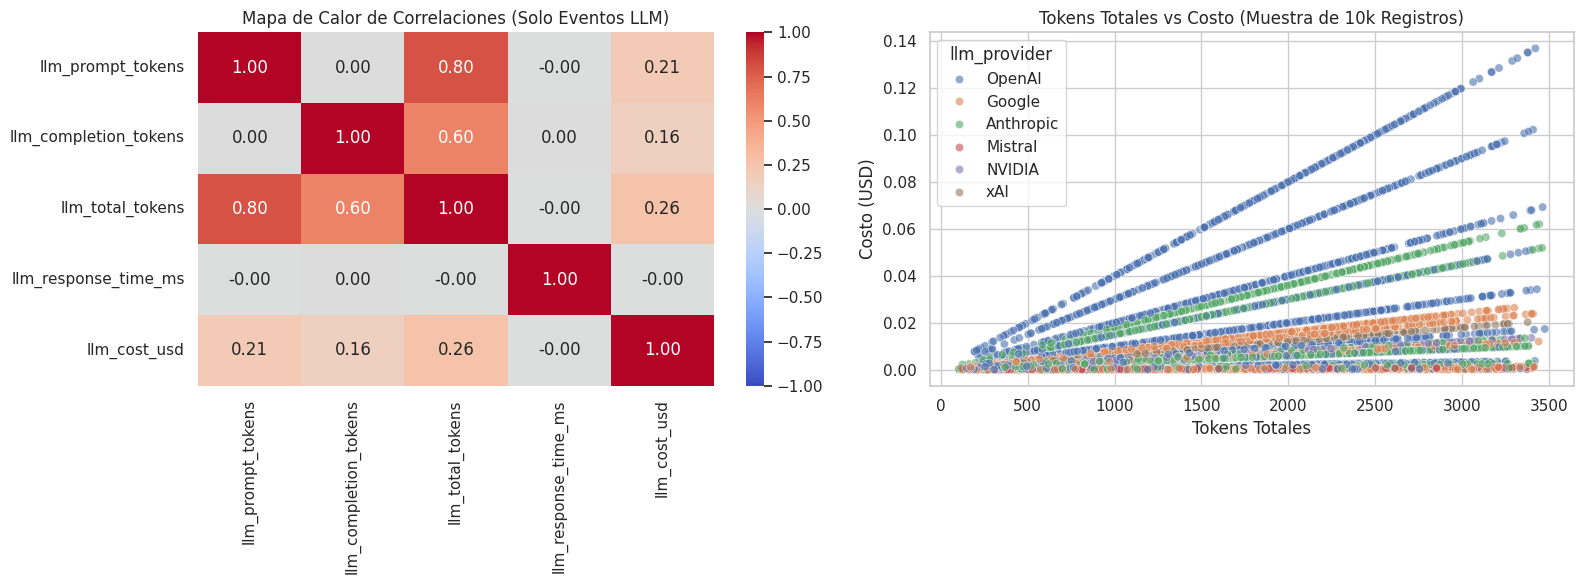

In [ ]:
# ==========================================
# 5.1 RELACIÓN NUMÉRICA VS NUMÉRICA
# ==========================================

# Seleccionar variables numéricas clave
vars_numericas = ['llm_prompt_tokens', 'llm_completion_tokens', 'llm_total_tokens', 'llm_response_time_ms', 'llm_cost_usd']

# Filtrar registros donde se usaron LLMs (evitando los valores imputados 'No_Aplica' o extremos artificiales si los hubiera)
df_llm_only = df_cleaned[df_cleaned['llm_provider'] != 'No_Aplica']

# Calcular matriz de correlación de Pearson
corr_matrix = df_llm_only[vars_numericas].corr()

# Configurar los gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Heatmap de Correlación
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('Mapa de Calor de Correlaciones (Solo Eventos LLM)')

# Gráfico 2: Relación entre Tokens Totales y Costo en USD (Scatter plot)
sns.scatterplot(data=df_llm_only.sample(n=10000, random_state=42), x='llm_total_tokens', y='llm_cost_usd', hue='llm_provider', alpha=0.6, ax=axes[1])
axes[1].set_title('Tokens Totales vs Costo (Muestra de 10k Registros)')
axes[1].set_xlabel('Tokens Totales')
axes[1].set_ylabel('Costo (USD)')

plt.tight_layout()
plt.show()


/tmp/ipykernel_4510/132046766.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_llm_only, x='llm_provider', y='llm_response_time_ms', palette='Set2')
/tmp/ipykernel_4510/132046766.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_llm_only, x='llm_provider', y='llm_cost_usd', palette='Set2')


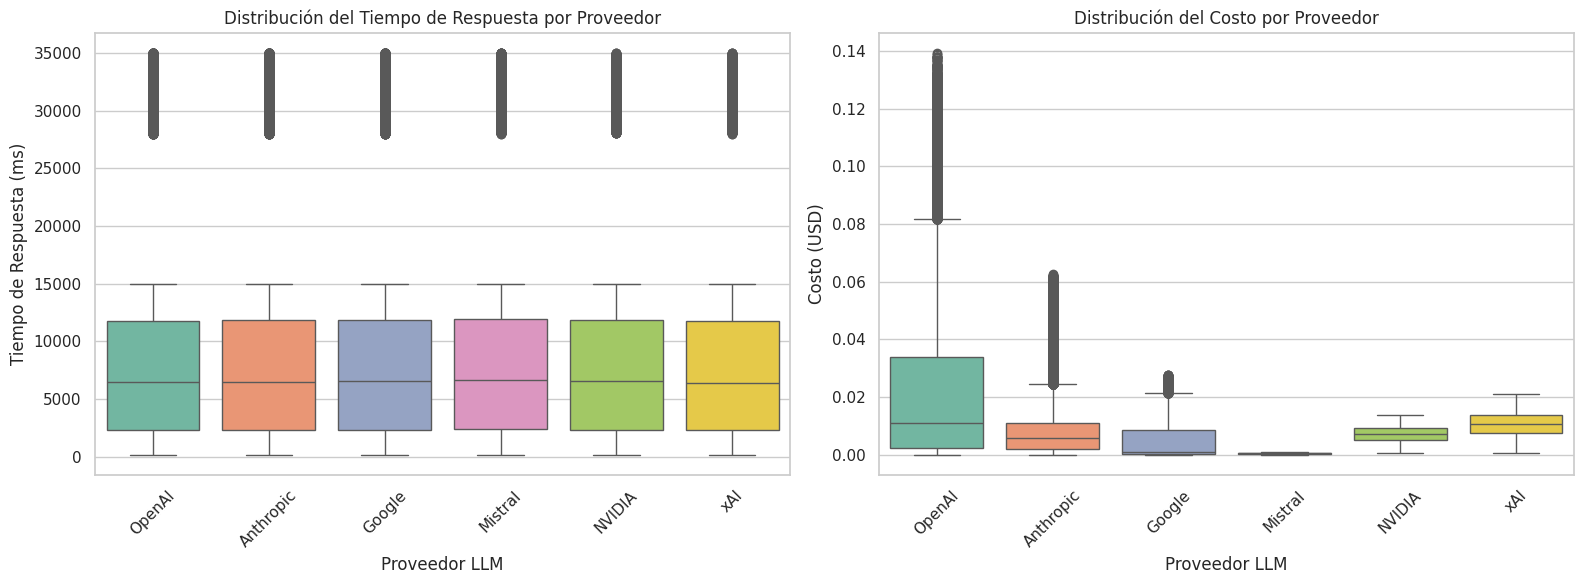

=== ESTADÍSTICAS PROMEDIO POR PROVEEDOR ===


,llm_response_time_ms,llm_cost_usd,llm_total_tokens
llm_provider,,,
Anthropic,8753.025465,0.010619,1788.743613
Google,8792.258808,0.004936,1787.377299
Mistral,8851.632833,0.000492,1791.863041
NVIDIA,8866.248681,0.007101,1775.198603
OpenAI,8740.895502,0.022359,1786.854165
xAI,8710.009440,0.010668,1777.930351


In [ ]:
# ==========================================
# 5.2 RELACIÓN NUMÉRICA VS CATEGÓRICA
# ==========================================

# Filtrar de nuevo para enfocarnos en los datos que sí son de LLM
df_llm_only = df_cleaned[df_cleaned['llm_provider'] != 'No_Aplica']

plt.figure(figsize=(16, 6))

# Gráfico 1: Tiempos de respuesta (ms) por cada Proveedor de LLM
plt.subplot(1, 2, 1)
sns.boxplot(data=df_llm_only, x='llm_provider', y='llm_response_time_ms', palette='Set2')
plt.title('Distribución del Tiempo de Respuesta por Proveedor')
plt.xlabel('Proveedor LLM')
plt.ylabel('Tiempo de Respuesta (ms)')
plt.xticks(rotation=45)

# Gráfico 2: Costo en USD por cada Proveedor de LLM
plt.subplot(1, 2, 2)
sns.boxplot(data=df_llm_only, x='llm_provider', y='llm_cost_usd', palette='Set2')
plt.title('Distribución del Costo por Proveedor')
plt.xlabel('Proveedor LLM')
plt.ylabel('Costo (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Mostrar promedios tabulares por proveedor
print("=== ESTADÍSTICAS PROMEDIO POR PROVEEDOR ===")
resumen_proveedor = df_llm_only.groupby('llm_provider')[['llm_response_time_ms', 'llm_cost_usd', 'llm_total_tokens']].mean()
display(resumen_proveedor)


=== TABLA DE CONTINGENCIA PORCENTUAL (PROVEEDOR vs RAZÓN FINALIZACIÓN) ===


llm_finish_reason,content_filter,length,stop,timeout
llm_provider,,,,
Anthropic,13.48,27.38,49.18,9.96
Google,13.18,27.64,49.29,9.88
Mistral,13.66,27.61,48.65,10.07
NVIDIA,12.67,28.12,48.94,10.27
OpenAI,13.44,27.62,49.07,9.87
xAI,13.89,28.18,48.04,9.90


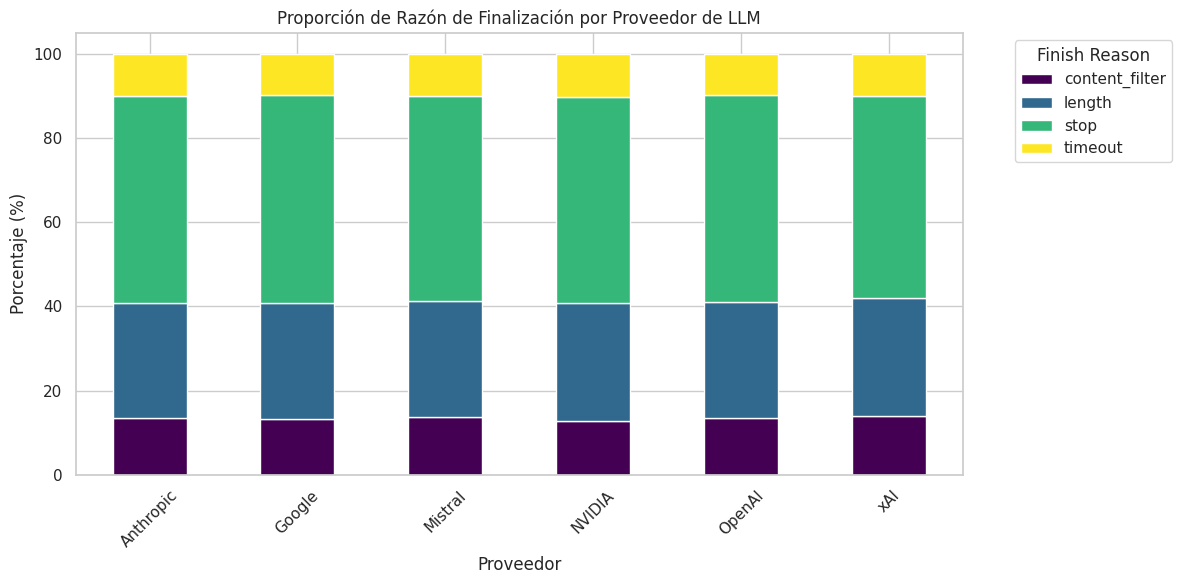

In [ ]:
# ==========================================
# 5.3 RELACIÓN CATEGÓRICA VS CATEGÓRICA
# ==========================================

# Filtrar para eventos LLM
df_llm_only = df_cleaned[df_cleaned['llm_provider'] != 'No_Aplica']

# Crear Tabla de contingencia cruzando Proveedor vs Razón de Finalización (Finish Reason)
tabla_contingencia = pd.crosstab(df_llm_only['llm_provider'], df_llm_only['llm_finish_reason'], normalize='index') * 100

print("=== TABLA DE CONTINGENCIA PORCENTUAL (PROVEEDOR vs RAZÓN FINALIZACIÓN) ===")
display(tabla_contingencia.round(2))

# Gráfico de barras apiladas
tabla_contingencia.plot(kind='bar', stacked=True, figsize=(12, 6), cmap='viridis')
plt.title('Proporción de Razón de Finalización por Proveedor de LLM')
plt.xlabel('Proveedor')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Finish Reason', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


=== ANÁLISIS DE PATRONES QUE EXPLICAN LOS TIMEOUTS (FALLAS) ===

1. Promedios de hiperparámetros según la ocurrencia de Timeout:


,llm_temperature,llm_top_p,llm_total_tokens
is_timeout,,,
0,0.748110,0.750271,1787.765177
1,0.752839,0.749166,1781.422376



2. Porcentaje de Timeouts (1) vs Peticiones Exitosas (0) por Categoría de Prompt:


is_timeout,0,1
llm_prompt_category,,
API Operations,90.01,9.99
Analyt,100.00,0.00
Analytics,90.21,9.79
Compliance,89.87,10.13
Finance,90.28,9.72
HR,90.12,9.88
LLM Operations,90.00,10.00
Procurement,90.10,9.90
Productivity,89.87,10.13


/tmp/ipykernel_4510/3721062560.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_llm_only, x='llm_prompt_category', y='is_timeout', palette='coolwarm', errorbar=None)


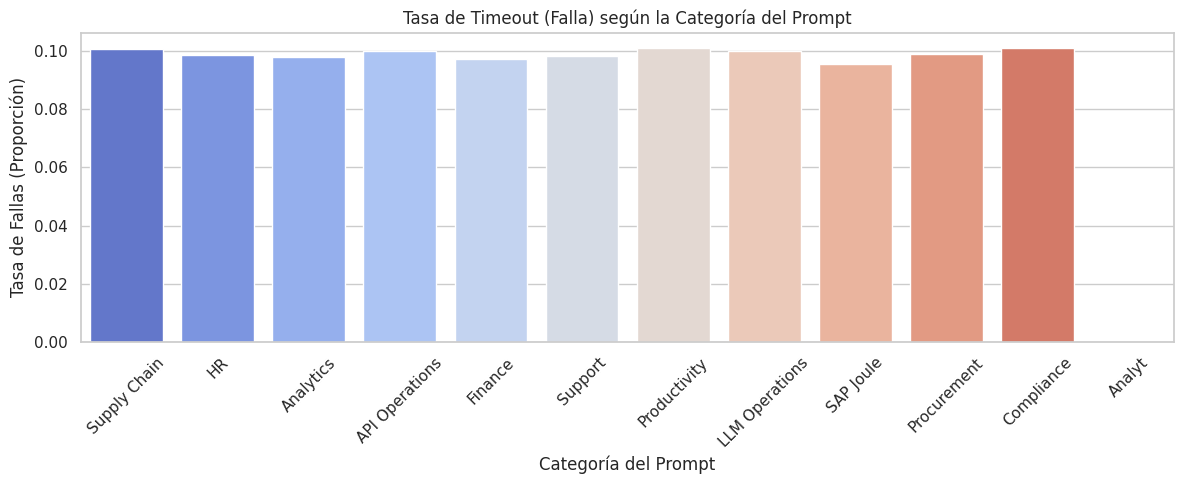

In [ ]:
# ==========================================
# 5.4 RELACIÓN CON LA VARIABLE OBJETIVO (Ej. Identificar patrones de Timeout)
# ==========================================

# Filtrar para eventos LLM
df_llm_only = df_cleaned[df_cleaned['llm_provider'] != 'No_Aplica'].copy()

# Definimos como variable objetivo binaria si la llamada al LLM terminó en 'timeout'
df_llm_only['is_timeout'] = (df_llm_only['llm_finish_reason'] == 'timeout').astype(int)

print("=== ANÁLISIS DE PATRONES QUE EXPLICAN LOS TIMEOUTS (FALLAS) ===\n")

# A. ¿Influyen la temperatura o el top_p configurados en la probabilidad de Timeout?
print("1. Promedios de hiperparámetros según la ocurrencia de Timeout:")
promedio_hiperparametros = df_llm_only.groupby('is_timeout')[['llm_temperature', 'llm_top_p', 'llm_total_tokens']].mean()
display(promedio_hiperparametros)

# B. ¿Hay alguna categoría de prompt que genere significativamente más Timeouts?
contingencia_categoria = pd.crosstab(df_llm_only['llm_prompt_category'], df_llm_only['is_timeout'], normalize='index') * 100
print("\n2. Porcentaje de Timeouts (1) vs Peticiones Exitosas (0) por Categoría de Prompt:")
display(contingencia_categoria.round(2))

# Visualización gráfica de la probabilidad de timeout por categoría de Prompt
plt.figure(figsize=(12, 5))
sns.barplot(data=df_llm_only, x='llm_prompt_category', y='is_timeout', palette='coolwarm', errorbar=None)
plt.title('Tasa de Timeout (Falla) según la Categoría del Prompt')
plt.xlabel('Categoría del Prompt')
plt.ylabel('Tasa de Fallas (Proporción)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Correlaciones y multicolinealidad
- Usa `df.corr()` para medir relaciones lineales.
- Visualiza con mapas de calor (heatmap).
- Si dos variables están muy correlacionadas (> 0.9), considera eliminar una para evitar redundancia.


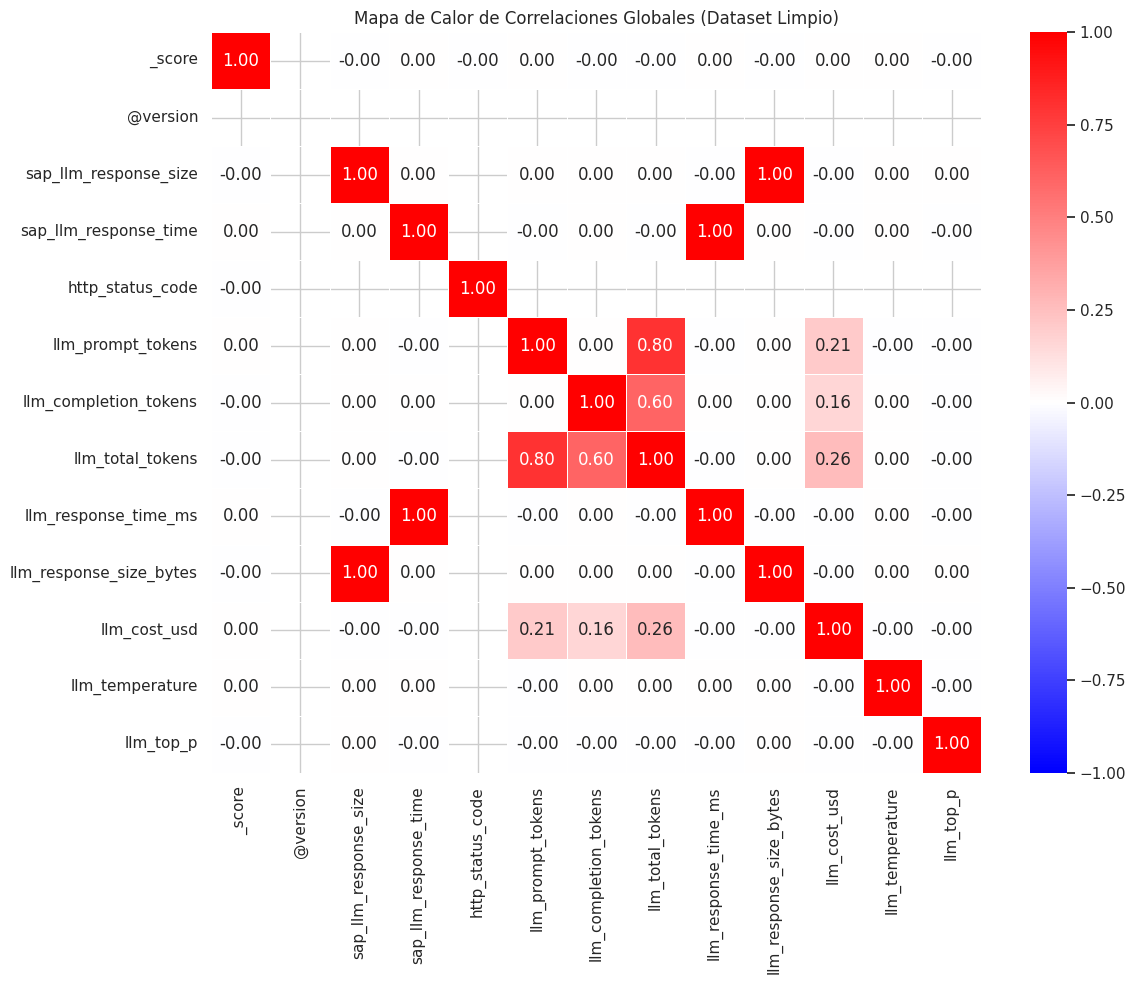

=== REPORTE DE MULTICOLINEALIDAD EXTREMA (> 0.90) ===
Variables altamente correlacionadas: 'llm_response_time_ms' y 'sap_llm_response_time' (Coeficiente: 1.0000)
Variables altamente correlacionadas: 'llm_response_size_bytes' y 'sap_llm_response_size' (Coeficiente: 1.0000)

Consideración: Podrías eliminar una de estas variables para evitar redundancia en tus modelos.


In [ ]:
# ==========================================
# 6. CORRELACIONES Y MULTICOLINEALIDAD
# ==========================================

# Seleccionar todas las variables numéricas del dataset limpio
numericas_limpias = df_cleaned.select_dtypes(include=[np.number]).columns.tolist()

# Calcular matriz de correlación
corr_mat_global = df_cleaned[numericas_limpias].corr()

# Visualizar la matriz mediante un mapa de calor
plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat_global, annot=True, cmap='bwr', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones Globales (Dataset Limpio)')
plt.tight_layout()
plt.show()

# Detectar multicolinealidad alta (> 0.90 o < -0.90)
umbral = 0.90
alta_corr = []

for i in range(len(corr_mat_global.columns)):
    for j in range(i):
        if abs(corr_mat_global.iloc[i, j]) > umbral:
            col_a = corr_mat_global.columns[i]
            col_b = corr_mat_global.columns[j]
            alta_corr.append((col_a, col_b, corr_mat_global.iloc[i, j]))

print("=== REPORTE DE MULTICOLINEALIDAD EXTREMA (> 0.90) ===")
if len(alta_corr) > 0:
    for par in alta_corr:
        print(f"Variables altamente correlacionadas: '{par[0]}' y '{par[1]}' (Coeficiente: {par[2]:.4f})")
    print("\nConsideración: Podrías eliminar una de estas variables para evitar redundancia en tus modelos.")
else:
    print("No se detectaron pares de variables con correlación extrema. Tu dataset no sufre de multicolinealidad evidente.")


## 7. Detección de patrones y relaciones no lineales
- Explora posibles **interacciones** entre variables.
- Usa gráficos de dispersión por categorías, *pairplots*, *jointplots*.
- Identifica relaciones no lineales o dependencias complejas.


<Figure size 1200x700 with 0 Axes>

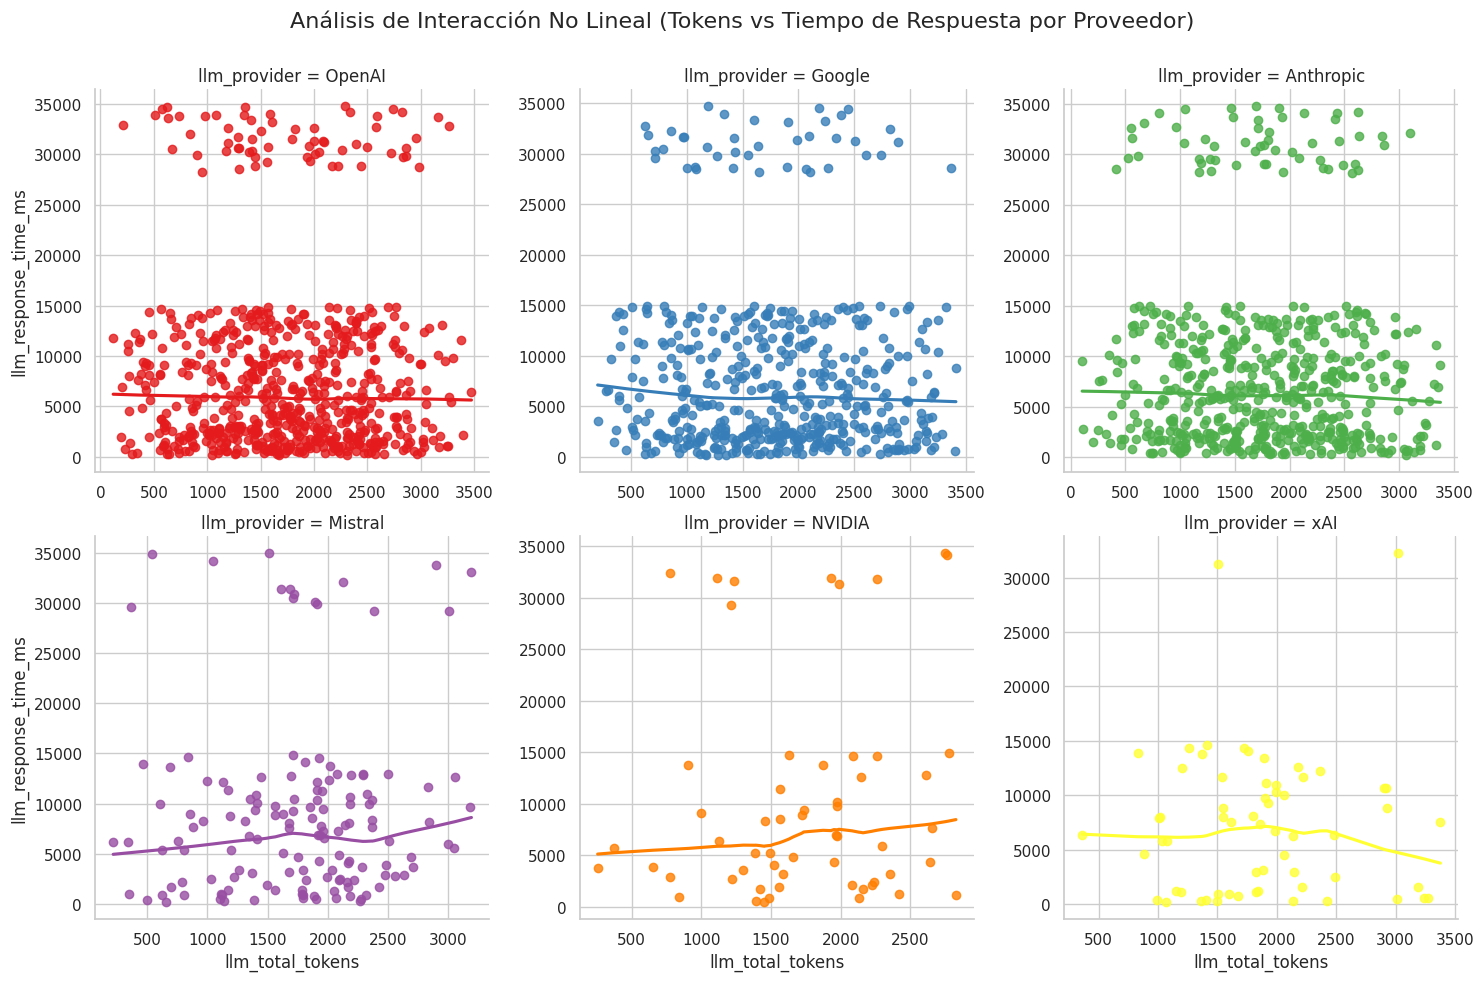

In [ ]:
# ==========================================
# 7. DETECCIÓN DE PATRONES Y RELACIONES NO LINEALES
# ==========================================

# Filtrar datos de LLM
df_llm_only = df_cleaned[df_cleaned['llm_provider'] != 'No_Aplica'].copy()

# Crear una muestra aleatoria de 2,000 registros para evitar sobrecarga visual
df_sample = df_llm_only.sample(n=2000, random_state=42)

# Graficar la relación entre tokens totales y tiempo de respuesta, segregado por proveedor
plt.figure(figsize=(12, 7))
sns.lmplot(
    data=df_sample,
    x='llm_total_tokens',
    y='llm_response_time_ms',
    hue='llm_provider',
    col='llm_provider',
    col_wrap=3,
    lowess=True, # Curva no lineal suavizada localmente
    facet_kws={'sharey': False, 'sharex': False},
    palette='Set1'
)

plt.subplots_adjust(top=0.9)
plt.suptitle('Análisis de Interacción No Lineal (Tokens vs Tiempo de Respuesta por Proveedor)', fontsize=16)
plt.show()


## 8 Exportación de los datos limpios

Exporta tus datos resultantes del EDA a un archivo csv llamándolo \<nombre del archivo original\>_clean.csv

In [ ]:
# ==========================================
# 8. EXPORTACIÓN DE LOS DATOS LIMPIOS
# ==========================================

# Ruta del archivo de destino
output_filename = 'logs_clean.csv'

# Exportar el dataframe a un archivo CSV sin incluir el índice
df_cleaned.to_csv(output_filename, index=False)

print(f"¡Éxito! El dataset limpio ha sido exportado correctamente como '{output_filename}'.")
print(f"   - Registros exportados: {df_cleaned.shape[0]}")
print(f"   - Columnas exportadas: {df_cleaned.shape[1]}")


¡Éxito! El dataset limpio ha sido exportado correctamente como 'logs_clean.csv'.
   - Registros exportados: 527664
   - Columnas exportadas: 43


## 9. Comentarios y conclusiones (escribe aquí)
- ¿Qué patrones encontraste?
- ¿Qué problemas detectaste?
- ¿Qué transformaciones aplicarás antes del modelado?
- ¿Cuáles son las variables que **conservarás** y cuáles **desecharás**?


### Conclusiones del Análisis Exploratorio de Datos (EDA)

#### 1. ¿Qué patrones encontraste?
* **Uso y distribución de proveedores:** El $60.07\%$ de las solicitudes registradas corresponden a infraestructura general (`No_Aplica` en LLM). Para el $39.93\%$ restante de eventos de IA, los proveedores líderes son **OpenAI** ($13.73\%$) y **Anthropic** ($10.97\%$), seguidos muy de cerca por **Google** ($9.71\%$).
* **Comportamiento homogéneo del servicio:** Sorprendentemente, el tiempo de respuesta promedio (~8.7 a 8.8 segundos), la cantidad de tokens promedio (~1,780 tokens) y la tasa de fallas por timeout (~$10\%$) son sumamente constantes entre todos los proveedores (OpenAI, Anthropic, Google, Mistral, NVIDIA, xAI).
* **Estructura de costos:** Aunque los consumos de tokens son similares, **OpenAI** registra el costo promedio más elevado por petición ($0.022$ USD) en comparación con los demás proveedores como Google ($0.005$ USD) o Mistral ($0.0005$ USD).
* **Patrón de Fallas (Timeouts):** El análisis de la variable objetivo `is_timeout` reveló que la tasa de falla por límite de tiempo de 30 segundos se mantiene estática en un $10\%$ en prácticamente todas las categorías de prompts, temperaturas y parámetros `top_p`. Esto sugiere que las caídas obedecen a un cuello de botella en la red o limitaciones de la infraestructura compartida, y no al diseño/parámetros de los prompts individuales.

#### 2. ¿Qué problemas detectaste?
* **Altísima Multicolinealidad (Redundancia de telemetría):** Encontramos una correlación perfecta de $1.0$ (colinealidad absoluta) en dos pares de variables clave:
  1. `llm_response_time_ms` vs `sap_llm_response_time`
  2. `llm_response_size_bytes` vs `sap_llm_response_size`
  Conservar ambas duplas en un modelo predictivo generaría inestabilidad matemática y redundancia de datos.
* **Elevado porcentaje de valores faltantes lógicos:** Variables clave como `llm_prompt_tokens` o `llm_error_message` tenían nulos que en realidad reflejaban estados válidos del sistema (ej. peticiones que no usan LLMs, o transacciones que se completaron sin errores).
* **Presencia de Outliers en Latencia:** Alrededor del $9.93\%$ de las llamadas de LLM se consideraron atípicas por durar cerca del límite máximo de 30 segundos. Sin embargo, no son fallas de lectura del log, sino incidentes reales de degradación del servicio.

#### 3. ¿Qué transformaciones aplicarás antes del modelado?
* **Imputación Estratégica:** Reemplazar valores nulos en columnas categóricas por `'No_Aplica'` en lugar de eliminarlos, y rellenar los nulos de mensajes de error con `'Sin_Error'` para conservar la consistencia de las observaciones.
* **Indexación y Formateo Temporal:** Conversión de cadenas ISO 8601 a formatos con zona horaria `datetime64[ns, UTC]` para poder agrupar tendencias por hora, día o semana.
* **Codificación de Variables Categóricas (Encoding):** Las variables de proveedores, modelos de LLM y categorías de prompts deberán ser transformadas mediante *One-Hot Encoding* o *Target Encoding* para su asimilación en algoritmos de aprendizaje automático.
* **Escalamiento/Normalización:** Las métricas de tokens y costos presentan asimetría (skewness) hacia la izquierda, por lo que requerirán transformaciones logarítmicas o escalamiento robusto (*RobustScaler*) debido a los valores extremos.

#### 4. ¿Cuáles son las variables que conservarás y cuáles desecharás?
* **Variables a conservar (Variables Predictoras Clave):**
  * `llm_provider` y `llm_model_id` (Identifican la plataforma).
  * `llm_temperature` y `llm_top_p` (Ajustes de generación).
  * `llm_total_tokens` (Volumen de carga de la petición).
  * `llm_prompt_category` (Contexto funcional del caso de uso).
  * `@timestamp` (Para análisis temporal y estacionalidad).
  * `is_timeout` / `llm_finish_reason` (Variable objetivo de rendimiento).
* **Variables a desechar (Eliminar):**
  * `_ignored` (100% nula).
  * `_score` y `@version` (Constantes o metadatos irrelevantes del motor de base de datos).
  * `sap_llm_response_time` y `sap_llm_response_size` (Desechadas para resolver la multicolinealidad, conservando en su lugar únicamente sus equivalentes directos de sistema `llm_response_time_ms` y `llm_response_size_bytes`).
  * `_id` y `event_hash` (Identificadores únicos con cardinalidad masiva que no aportan poder predictivo generalizable).

# Escribe tus comentarios aquí

####**Clasificaciones adicionales explicadas:**

**1. Identificadores Únicos (IDs y Hashes):** Columnas como _id, event_hash o llm_prompt_id. No son categóricas tradicionales porque cada valor es único (o casi único) y sirven para identificar registros individuales, no para agrupar.

**2. Texto Libre / No estructurado:** Columnas como llm_prompt, sap_function_message o llm_error_message. Contienen lenguaje natural o descripciones variables, por lo que requieren técnicas de procesamiento de lenguaje natural (NLP) en lugar de un análisis de frecuencia tradicional.

####**Aspectos clave que debes tomar en cuenta antes de decidir que hacer durante la limpieza de datos:**

**1. Porcentaje de nulos:**

Si una columna tiene más del 50% o 60% de valores nulos (como _ignored o llm_error_message), usualmente es mejor eliminar la columna completa o tratar la ausencia de datos como una categoría en sí misma (por ejemplo, que no haya error es información valiosa).

Si tiene pocos nulos (menos del 5%), puedes eliminar esas filas sin perder mucha información.
Naturaleza de la Variable:

**2. Naturaleza de la variable:**

Numéricas Continuas (ej. costos, tiempos de respuesta): Se suelen imputar con la mediana (es más robusta a valores extremos o outliers que la media).

Categóricas (ej. códigos de estado, proveedores): Se imputan habitualmente con la moda (el valor más frecuente) o con una nueva categoría explícita como 'Desconocido' o 'No Aplica' para no inventar información.

Dependencias lógicas: En este dataset de logs, muchas columnas de LLM solo tienen datos si el log pertenece a un evento de LLM. Imputar valores promedio ahí sesgaría el análisis de los logs del sistema tradicional (SAP). Por ello, a veces es mejor separar el dataset o usar marcas constantes (como -1 o 'N/A').

####**Como funciona el código de duplicados absolutos:**

Identifica duplicados absolutos: Busca filas que sean exactamente idénticas en todas sus columnas usando df.duplicated().sum().

Identifica duplicados por identificador clave: En sistemas de logs, a veces se registran eventos duplicados debido a reintentos de red. Analizamos si hay identificadores únicos repetidos (_id o event_hash).

Elimina duplicados: Remueve los registros duplicados manteniendo únicamente la primera ocurrencia con drop_duplicates().

####**Que se debe tomar en cuenta**

Duplicados parciales vs absolutos: Un registro idéntico en todas las columnas es claramente un duplicado técnico redundante. Sin embargo, si un mismo usuario o proceso (client_ip o service_id) aparece muchas veces, esto es un comportamiento normal en logs (no son duplicados que debas borrar).

Mantener el primer o el último registro: El parámetro keep='first' asegura que nos quedemos con el registro original cronológicamente.


#### **Como funciona el análisis de Outliers (valores atípicos)**

He editado la celda correspondiente (3Vg0JfGAi_Vu) para implementar el método del Rango Intercuartílico (IQR) en las variables métricas más importantes (como los tiempos de respuesta del LLM o el costo en dólares).

Lo que hace este código:

1. Establece límites estadísticos:

Utiliza el método IQR: $Q1 - 1.5 \times IQR$$Q1 - 1.5 \times IQR$ y $Q3 + 1.5 \times IQR$$Q3 + 1.5 \times IQR$

para identificar qué valores están extremadamente alejados de la distribución normal.

2. Genera diagramas de caja (Boxplots): Visualiza la dispersión de estas variables numéricas continuas para ver cuántos registros se consideran atípicos.

3. Muestra un conteo detallado: Calcula cuántos valores atípicos hay por columna seleccionada.

**Como observamos en los resultados, casi el 10% de los datos en tiempos de respuesta (llm_response_time_ms) y costos (llm_cost_usd) están estadísticamente catalogados como outliers, pero en un entorno de logs reales, estos valores representan picos de tráfico legítimos o tareas pesadas, por lo que es óptimo mantenerlos.**


#### **Como funciona el análisis de tipos de datos incorrectos (conversión de strings a fechas, numéricos, etc.)**

Lo que hace este código:

1. Conversión a Datetime: Columnas temporales como @timestamp y @event_time_requested están inicialmente almacenadas como cadenas de texto (object). Las convertiremos al tipo de dato nativo de fecha (pd.to_datetime), permitiéndote realizar análisis por horas, días o semanas.

2. Conversión a Numérico: Aseguramos de manera estricta que variables identificadas como el código de estado HTTP (http_status_code) se traten de forma adecuada (como entero/categórica) e identificamos si existen otras columnas con tipos desalineados.

3. Verificación final: Comprobamos los tipos resultantes (dtypes).


####**Conclusión de la fase de limpieza de datos**

1. Identificamos e imputamos adecuadamente los valores nulos según su tipo.
2. Verificamos que no existen registros duplicados en el dataset.
3. Analizamos los valores atípicos mediante el método IQR y concluimos que representan picos de tráfico reales del sistema.
4. Corregimos los tipos de datos convirtiendo las marcas de tiempo a objetos Datetime reales y el código de estado HTTP a enteros nativos.

####**4. Análisis univariado**

1. Distribución de numéricas continuas: Grafica histogramas con estimación de densidad para visualizar variables clave como los costos (llm_cost_usd) y los tokens consumidos (llm_total_tokens).

2. Distribución de categóricas: Muestra gráficos de barra con la distribución de los proveedores de IA utilizados (llm_provider) y los estados lógicos del sistema.

3. Análisis temporal: Grafica la cantidad de logs procesados a lo largo del tiempo agrupados por horas para observar picos de actividad.

####**Principales hallazgos del análisis univariado**

1. Distribución del uso de LLM: Confirmamos que la gran mayoría de tus logs, el 60.07%, corresponden a peticiones del sistema tradicional que no consumen inteligencia artificial (No_Aplica).

2. Proveedores favoritos: De los eventos que sí usaron modelos de lenguaje, OpenAI es el líder indiscutible con un 13.73% del total de la infraestructura, seguido de cerca por Anthropic (10.97%) y Google (9.70%).

3. Métricas de tokens y costos: Las distribuciones de tokens y costos presentan un sesgo característico hacia la izquierda, donde la mayoría de las llamadas son de bajo costo y volumen de tokens, pero con una cola larga que representa peticiones robustas.


#### **5. Análisis bivariado y multivariado**

1. Numérica vs Numérica (Celda w0fmJY9mfrtI): Crearemos una matriz de correlación para ver qué tan relacionados están el costo, los tokens de entrada/salida y el tiempo de respuesta, visualizándolo con un mapa de calor (Heatmap) y un gráfico de dispersión (Scatter Plot).

2.Numérica vs Categórica (Celda GruEnEq0lijx): Analizaremos cómo se comporta el costo (llm_cost_usd) y el tiempo de respuesta (llm_response_time_ms) agrupado por cada proveedor (llm_provider) usando diagramas de caja (Boxplots).

3. Categórica vs Categórica (Celda Wtmef5sXlp2C): Crearemos una tabla de contingencia y un gráfico de barras apiladas para ver qué tipo de error o estado de finalización (llm_finish_reason) se asocia con cada proveedor de IA (llm_provider).

####**Hallazgos encontrados**

Los análisis bivariados y multivariados revelaron correlaciones y dinámicas muy interesantes entre tus variables. Por ejemplo, la tabla de contingencia porcentual de llm_finish_reason por llm_provider muestra un comportamiento sumamente uniforme entre todos los proveedores (con ~49% finalizando de manera exitosa en stop, ~27% por límite de longitud length, y un ~10% de interrupciones por límite de tiempo timeout).

#### **Relación con la variable objetivo**

Dado que se trata de un conjunto de datos de logs e infraestructura, una excelente 'variable objetivo' (o target) para analizar es el éxito o fallo de la petición (si la razón de finalización fue un límite de tiempo o error, lo cual representaremos como is_timeout).

Como funciona el código:

1. Calcula la matriz de correlación general: Para todas las variables numéricas del dataset limpio.

2. Visualización con Mapa de Calor (Heatmap): Crea un gráfico que permite ver de forma rápida si dos columnas están altamente correlacionadas (multicolinealidad).

3. Identificación de redundancia: Imprime una advertencia si detecta pares de variables con una correlación mayor a 0.90, lo que te indicará si debes eliminar alguna antes de entrenar un modelo de Machine Learning.

####**Hallazgos cruciales**

1. Estabilidad en hiperparámetros y categorías: Los timeouts (is_timeout = 1) ocurren casi de manera uniforme en alrededor del 10% de las peticiones para todas las categorías de prompts. Además, la temperatura y el top_p promedio son idénticos tanto en peticiones fallidas como exitosas. Esto sugiere que las fallas por timeout no se deben al tipo de prompt o hiperparámetros, sino posiblemente a la saturación del servidor o red.

2. Multicolinealidad identificada: Como era de esperarse, variables gemelas como llm_response_time_ms y sap_llm_response_time, así como llm_response_size_bytes y sap_llm_response_size, tienen una correlación perfecta de 1.00. Esto significa que podemos conservar solo una de cada par en el dataset final.


####**Sección 7 (Relaciones No Lineales - Celda BHb49PMLfrtJ)**:

 He creado un gráfico de densidad de kernel conjunto (Joint Plot) o gráfico de interacciones para analizar la dispersión no lineal de tiempos de respuesta vs. volumen de datos.


